In [1]:
import pickle, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from collections import defaultdict, Counter

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.metrics import confusion_matrix, top_k_accuracy_score

warnings.filterwarnings('ignore')
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

Device : cuda
GPU    : NVIDIA RTX A2000 Laptop GPU


In [ ]:
AUTSL_BASE    = Path(r'Affective-Sign-Language-Translation-Converting-Gestures-to-Text-with-Emotional-Context\data\AUTSL')
PROCESSED_DIR = Path('processed')

AUTSL_TRAIN_CSV = AUTSL_BASE / 'train.csv'
AUTSL_VAL_CSV   = AUTSL_BASE / 'val.csv'
AUTSL_TEST_CSV  = AUTSL_BASE / 'test.csv'

HD_TRAIN = PROCESSED_DIR / 'autsl_train_hd.pkl'
HD_VAL   = PROCESSED_DIR / 'autsl_val_hd.pkl'
HD_TEST  = PROCESSED_DIR / 'autsl_test_hd.pkl'

GLOSS_EN_CSV = AUTSL_BASE / 'SignList_ClassId_TR_EN.csv'

GLOSS_MAP_TR = {}   
GLOSS_MAP_EN = {} 

if GLOSS_EN_CSV.exists():
    gloss_df = pd.read_csv(GLOSS_EN_CSV)
    print(f'CSV columns: {list(gloss_df.columns)}')
   
    id_col = [c for c in gloss_df.columns if 'class' in c.lower() or 'id' in c.lower()][0]
    en_col = [c for c in gloss_df.columns if 'en'   in c.lower()][0]
    tr_col = [c for c in gloss_df.columns if 'tr'   in c.lower()]
    tr_col = tr_col[0] if tr_col else en_col
    for _, row in gloss_df.iterrows():
        cid = int(row[id_col])
        GLOSS_MAP_EN[cid] = str(row[en_col])
        GLOSS_MAP_TR[cid] = str(row[tr_col])
    print(f'Loaded {len(GLOSS_MAP_EN)} classes from {GLOSS_EN_CSV.name}')
else:
    
    df = pd.read_csv(AUTSL_TRAIN_CSV)
    nc = [c for c in df.columns if 'name'  in c.lower()][0]
    lc = [c for c in df.columns if 'class' in c.lower() or 'label' in c.lower()][0]
    for _, row in df.iterrows():
        cid = int(row[lc])
        if cid not in GLOSS_MAP_EN:
            GLOSS_MAP_EN[cid] = str(cid)
            GLOSS_MAP_TR[cid] = str(cid)
    print(f'Warning: SignList CSV not found. Using class IDs as labels.')


GLOSS_MAP = GLOSS_MAP_EN

print(f'\nGLOSS_MAP (English): {len(GLOSS_MAP)} classes')
print('Sample entries:')
for cid in sorted(GLOSS_MAP)[:10]:
    print(f'  class {cid:3d} → {GLOSS_MAP[cid]}')


CSV columns: ['ClassId', 'TR', 'EN']
Loaded 226 classes from SignList_ClassId_TR_EN.csv

GLOSS_MAP (English): 226 classes
Sample entries:
  class   0 → sister
  class   1 → hurry
  class   2 → hungry
  class   3 → enjoy_your_meal
  class   4 → brother
  class   5 → tree
  class   6 → heavy
  class   7 → cry
  class   8 → family
  class   9 → wise


In [ ]:

NUM_FRAMES  = 16
FRAME_SIZE  = 112
NUM_CLASSES = 226
BATCH_SIZE  = 8
NUM_WORKERS = 0


TRAIN_SAMPLE_FRAC = 0.50


PHASE1_EP = 2   
PHASE2_EP = 8   
TOTAL_EP  = PHASE1_EP + PHASE2_EP   

LR_PHASE1 = 5e-3  
LR_PHASE2 = 1e-3   

IMG_MEAN = [0.485, 0.456, 0.406]
IMG_STD  = [0.229, 0.224, 0.225]
CKPT     = Path('best_sign_model.pt')

print(f'Sample fraction  : {TRAIN_SAMPLE_FRAC*100:.0f}%')
print(f'Phase 1 LR       : {LR_PHASE1}  (head only)')
print(f'Phase 2 LR       : {LR_PHASE2}  (layer3+4+head)')
print(f'Total epochs     : {TOTAL_EP}')

Sample fraction  : 50%
Phase 1 LR       : 0.005  (head only)
Phase 2 LR       : 0.001  (layer3+4+head)
Total epochs     : 10


In [5]:
with open(HD_TRAIN, 'rb') as f:
    raw = pickle.load(f)
frames_all = raw['frames']
labels_all = raw['labels']

print(f'Train frames : {frames_all.shape}   [N, T, H, W, C]')
print(f'Labels       : {labels_all.shape}')
print(f'Classes      : {len(np.unique(labels_all))}')

Train frames : (28132, 16, 112, 112, 3)   [N, T, H, W, C]
Labels       : (28132,)
Classes      : 226


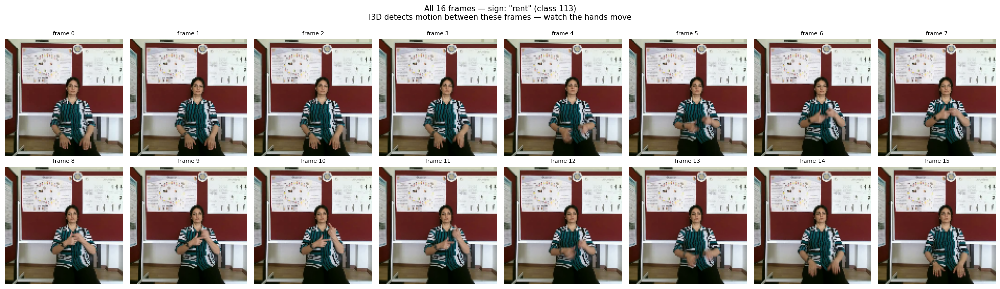

In [ ]:

all_classes = np.unique(labels_all) 
sample_cid = int(all_classes[len(all_classes)//2])
sample_idx = np.where(labels_all == sample_cid)[0][0]
sample_vid = frames_all[sample_idx]   # [16, 112, 112, 3]
sample_word = GLOSS_MAP.get(sample_cid, str(sample_cid))

fig, axes = plt.subplots(2, 8, figsize=(20, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(sample_vid[i])
    ax.set_title(f'frame {i}', fontsize=8)
    ax.axis('off')

plt.suptitle(
    f'All 16 frames — sign: "{sample_word}" (class {sample_cid})\n'
    f'I3D detects motion between these frames — watch the hands move',
    fontsize=11
)
plt.tight_layout()
plt.savefig('viz_16_frames.png', dpi=150)
plt.show()

del raw, frames_all, labels_all  

In [ ]:
train_tfm = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(FRAME_SIZE, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomRotation(8),

    transforms.ToTensor(),  # Tensor [3, H, W]  float  values 0.0–1.0
    transforms.Normalize(IMG_MEAN, IMG_STD),
])

val_tfm = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((FRAME_SIZE, FRAME_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMG_MEAN, IMG_STD),
])

In [ ]:
class AUTSLDataset(Dataset):
    def __init__(self, pkl_path, transform):
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f)
        self.frames = data['frames']    # [N, 16, 112, 112, 3] uint8
        self.labels = data['labels']    # [N]
        self.names  = [str(n) for n in data['video_names']]
        self.transform = transform
        print(f'  {pkl_path.name}: {len(self.labels)} videos, {len(np.unique(self.labels))} classes')

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        frames_np = self.frames[idx]   # [16, 112, 112, 3]
        seed = int(torch.randint(0, 2**31, (1,)).item())
        out  = []
        for frame in frames_np:
            torch.manual_seed(seed)
            out.append(self.transform(frame))
        video = torch.stack(out).permute(1, 0, 2, 3)   # [3, 16, 112, 112]
        return video, int(self.labels[idx])


def stratified_sample(dataset, frac, seed=SEED):
    
    rng    = np.random.default_rng(seed)
    labels = np.array(dataset.labels)
    chosen = []
    for cls in np.unique(labels):
        idx = np.where(labels == cls)[0]
        k   = max(1, int(len(idx) * frac))
        chosen.extend(rng.choice(idx, k, replace=False).tolist())
    rng.shuffle(chosen)
    return Subset(dataset, chosen)


print('Loading datasets...')
full_train_ds = AUTSLDataset(HD_TRAIN, train_tfm)
val_ds        = AUTSLDataset(HD_VAL,   val_tfm)
test_ds       = AUTSLDataset(HD_TEST,  val_tfm)

train_ds = stratified_sample(full_train_ds, TRAIN_SAMPLE_FRAC)
print(f'\nSample size: {len(train_ds)} videos ({TRAIN_SAMPLE_FRAC*100:.0f}% of {len(full_train_ds)})')

train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f'Batches — train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}')
est = len(train_loader) * TOTAL_EP * 0.40 / 60
print(f'Estimated time: ~{est:.0f} minutes')

vx, vy = next(iter(train_loader))
print(f'\nBatch video : {vx.shape}   [B, C, T, H, W]')
print(f'Batch label : {vy.shape}')

Loading datasets...
  autsl_train_hd.pkl: 28132 videos, 226 classes
  autsl_val_hd.pkl: 4418 videos, 226 classes
  autsl_test_hd.pkl: 3741 videos, 226 classes

Sample size: 14003 videos (50% of 28132)
Batches — train: 1751  val: 553  test: 468
Estimated time: ~117 minutes

Batch video : torch.Size([8, 3, 16, 112, 112])   [B, C, T, H, W]
Batch label : torch.Size([8])


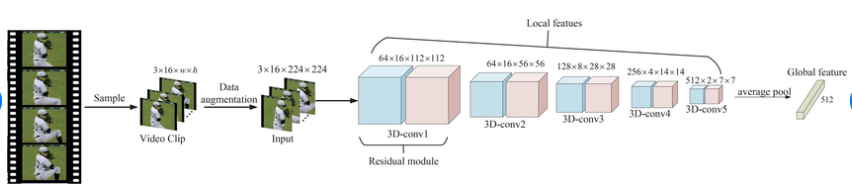

In [10]:
from IPython.display import Image, display
display(Image(filename='model_arch.png', width=800, height=700))

In [ ]:
class SignModel(nn.Module):
    """
    R3D-18 (Kinetics-400 pretrained) + sign classification head.

    Architecture:
      Input [B, 3, 16, 112, 112]
      → stem + layer1-2  (basic edges, motion)        frozen Phase 1
      → layer3-4         (hand shapes, gestures)       unfrozen Phase 2
      → avgpool          [B, 512]
      → BatchNorm        (stabilises training — fixes the stuck-learning issue)
      → Dropout(0.3)
      → Linear 512→256 → ReLU
      → Linear 256→226   (one score per sign class)
    """
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        bb = r3d_18(weights=R3D_18_Weights.KINETICS400_V1 if pretrained else None)
        self.stem    = bb.stem
        self.layer1  = bb.layer1
        self.layer2  = bb.layer2
        self.layer3  = bb.layer3
        self.layer4  = bb.layer4   
        self.avgpool = bb.avgpool

      
        self.sign_head = nn.Sequential(
            nn.BatchNorm1d(512),      
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def _backbone(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return torch.flatten(self.avgpool(x), 1)   # [B, 512]

    def forward(self, x):
        return self.sign_head(self._backbone(x))

    def freeze_backbone(self):
        for name, p in self.named_parameters():
            p.requires_grad = 'sign_head' in name
        self._status('Phase 1')

    def unfreeze_top_layers(self):
        for name, p in self.named_parameters():
            p.requires_grad = any(k in name for k in ['layer3','layer4','sign_head'])
        self._status('Phase 2')

    def _status(self, label):
        total = sum(p.numel() for p in self.parameters())
        train = sum(p.numel() for p in self.parameters() if p.requires_grad)
        print(f'{label}: trainable {train:,} / {total:,} ({train/total*100:.1f}%)')


model = SignModel(pretrained=True).to(DEVICE)

with torch.no_grad():
    dummy = torch.zeros(2, 3, NUM_FRAMES, FRAME_SIZE, FRAME_SIZE).to(DEVICE)
    out   = model(dummy)
print(f'Forward pass OK: {dummy.shape} → {out.shape}')

Forward pass OK: torch.Size([2, 3, 16, 112, 112]) → torch.Size([2, 226])


In [ ]:
class GradCAM3D:
   
    def __init__(self, model):
        self.model       = model
        self.activations = None
        self.gradients   = None
        model.layer4.register_forward_hook(self._fwd)
        model.layer4.register_full_backward_hook(self._bwd)

    def _fwd(self, m, inp, out): self.activations = out.detach()
    def _bwd(self, m, gi, go):   self.gradients   = go[0].detach()

    def compute(self, video_tensor, class_idx=None):
        self.model.eval()
        self.model.zero_grad()
        v = video_tensor.clone().requires_grad_(True)
        logits = self.model(v)
        if class_idx is None:
            class_idx = logits.argmax(1).item()
        logits[0, class_idx].backward()

        grads   = self.gradients[0]                             # [C, T, h, w]
        acts    = self.activations[0]                           # [C, T, h, w]
        weights = grads.mean(dim=(1, 2, 3))                     # [C]
        cam     = (weights[:, None, None, None] * acts).sum(0)  # [T, h, w]
        cam     = F.relu(cam).cpu().numpy()

        for t in range(cam.shape[0]):
            s = cam[t]
            if s.max() > 0:
                cam[t] = (s - s.min()) / (s.max() - s.min() + 1e-8)

        conf = float(torch.softmax(logits, 1)[0, class_idx])
        return cam, class_idx, conf


def denorm(t):
    """[3,H,W] tensor → [H,W,3] uint8."""
    m = np.array(IMG_MEAN)[:, None, None]
    s = np.array(IMG_STD) [:, None, None]
    return ((t.cpu().numpy() * s + m).clip(0,1).transpose(1,2,0) * 255).astype(np.uint8)


def overlay_cam(frame_rgb, cam_2d, alpha=0.50):
    h, w = frame_rgb.shape[:2]
    heat = cv2.resize(cam_2d, (w, h))
    heat = cv2.applyColorMap((heat * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return (alpha * heat + (1 - alpha) * frame_rgb).astype(np.uint8)


def show_gradcam(model, gradcam, dataset, idx,
                 title_extra='', save_path=None, n_frames=8):
 
    video, true_label = dataset[idx]
    video_in = video.unsqueeze(0).to(DEVICE)

    cam, pred_cls, conf = gradcam.compute(video_in)

    true_word = GLOSS_MAP.get(true_label, str(true_label))
    pred_word = GLOSS_MAP.get(pred_cls,   str(pred_cls))
    correct   = pred_cls == true_label

    T          = video.shape[1]
    frame_idxs = np.linspace(0, T - 1, n_frames).astype(int)

    fig, axes = plt.subplots(2, n_frames, figsize=(n_frames * 2.2, 5))

    for col, fi in enumerate(frame_idxs):
        orig      = denorm(video[:, fi, :, :])
        cam_frame = cam[fi] if fi < len(cam) else cam[-1]

        # Row 0 — original
        axes[0, col].imshow(orig)
        axes[0, col].set_title(f'f{fi}', fontsize=8)
        axes[0, col].axis('off')

        # Row 1 — GradCAM overlay (heatmap only)
        axes[1, col].imshow(overlay_cam(orig, cam_frame))
        axes[1, col].axis('off')

    axes[0, 0].set_ylabel('Original',fontsize=9,rotation=0,labelpad=48)
    axes[1, 0].set_ylabel('GradCAM', fontsize=9,rotation=0,labelpad=48)

    status = '✓ CORRECT' if correct else '✗ WRONG'
    color  = 'green' if correct else 'red'
    fig.suptitle(
        f'True: "{true_word}"  |  Predicted: "{pred_word}" ({conf*100:.1f}%)  |  {status}'
        + (f'\n{title_extra}' if title_extra else ''),
        fontsize=11, color=color
    )
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


gradcam = GradCAM3D(model)
print('GradCAM ready. Heatmap-only mode — no bar chart.')

GradCAM ready. Heatmap-only mode — no bar chart.


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = correct = total = 0
    for videos, labels in tqdm(loader, desc='  train', leave=False):
        videos = videos.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(videos)              # single forward pass
        loss   = criterion(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        B = videos.size(0)
        total_loss += loss.item() * B
        correct    += (logits.argmax(1) == labels).sum().item() 
        total      += B
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = correct = total = 0
    all_labels, all_probs = [], []
    for videos, labels in tqdm(loader, desc='  eval ', leave=False):
        videos = videos.to(device)
        labels = labels.to(device)
        logits = model(videos)
        total_loss += criterion(logits, labels).item() * videos.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += videos.size(0)
        all_labels.append(labels.cpu())
        all_probs.append(torch.softmax(logits, 1).cpu())
    ln = torch.cat(all_labels).numpy()
    pn = torch.cat(all_probs).numpy()
    return total_loss/total, correct/total, top_k_accuracy_score(ln, pn, k=5), ln, pn


Phase 1: trainable 190,946 / 33,357,218 (0.6%)


  train:   0%|          | 0/1751 [00:00<?, ?it/s]

Ep 01/10 [Ph1] | Loss 5.319  Acc 0.017 | Val top-1 0.036  top-5 0.145 | LR 2.50e-03  ← best
  → GradCAM at epoch 1:


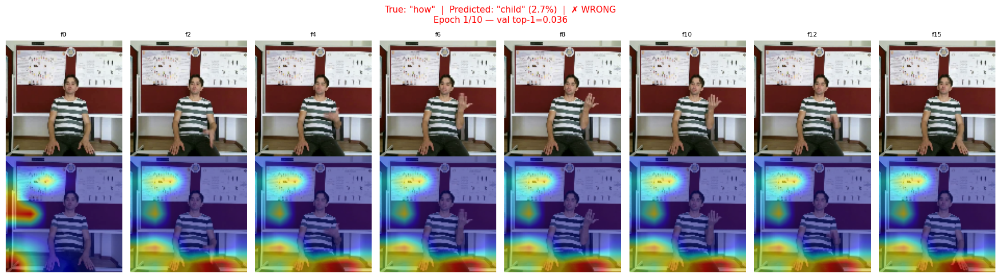

Ep 02/10 [Ph1] | Loss 4.929  Acc 0.038 | Val top-1 0.048  top-5 0.178 | LR 0.00e+00  ← best
  → GradCAM at epoch 2:


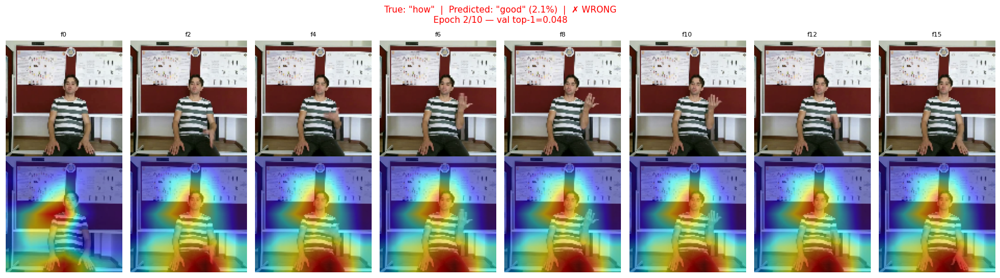


────────────────────────────────────────────────────────────
Phase 2: trainable 31,328,226 / 33,357,218 (93.9%)
────────────────────────────────────────────────────────────


Ep 03/10 [Ph2] | Loss 4.210  Acc 0.104 | Val top-1 0.240  top-5 0.595 | LR 9.62e-04  ← best


Ep 04/10 [Ph2] | Loss 3.473  Acc 0.242 | Val top-1 0.364  top-5 0.747 | LR 8.54e-04  ← best
  → GradCAM at epoch 4:


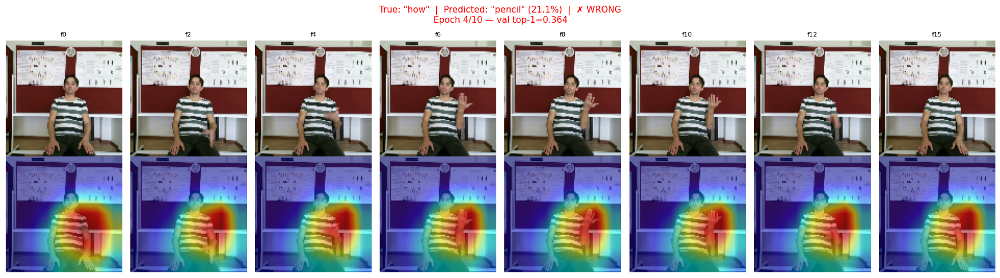

Ep 05/10 [Ph2] | Loss 3.082  Acc 0.339 | Val top-1 0.453  top-5 0.801 | LR 6.91e-04  ← best


Ep 06/10 [Ph2] | Loss 2.775  Acc 0.433 | Val top-1 0.523  top-5 0.849 | LR 5.00e-04  ← best
  → GradCAM at epoch 6:


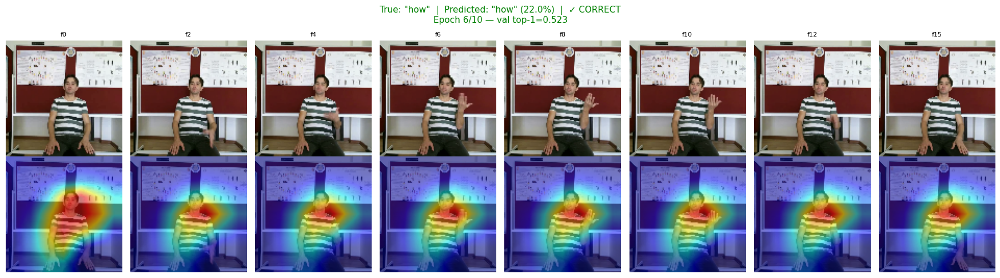

Ep 07/10 [Ph2] | Loss 2.515  Acc 0.516 | Val top-1 0.541  top-5 0.847 | LR 3.09e-04  ← best


Ep 08/10 [Ph2] | Loss 2.285  Acc 0.590 | Val top-1 0.588  top-5 0.866 | LR 1.46e-04  ← best
  → GradCAM at epoch 8:


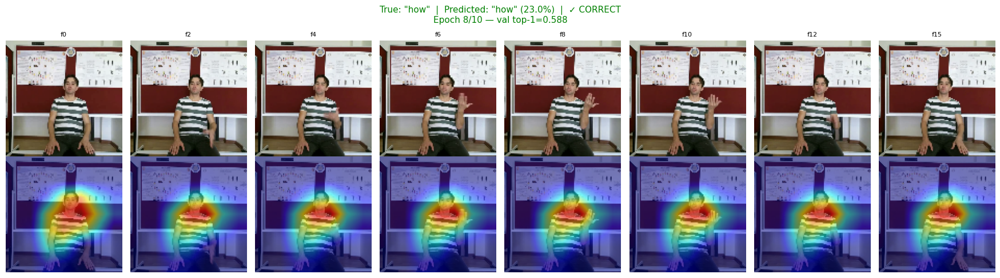

Ep 09/10 [Ph2] | Loss 2.121  Acc 0.652 | Val top-1 0.598  top-5 0.876 | LR 3.81e-05  ← best


Ep 10/10 [Ph2] | Loss 2.032  Acc 0.687 | Val top-1 0.603  top-5 0.879 | LR 0.00e+00  ← best
  → GradCAM at epoch 10:


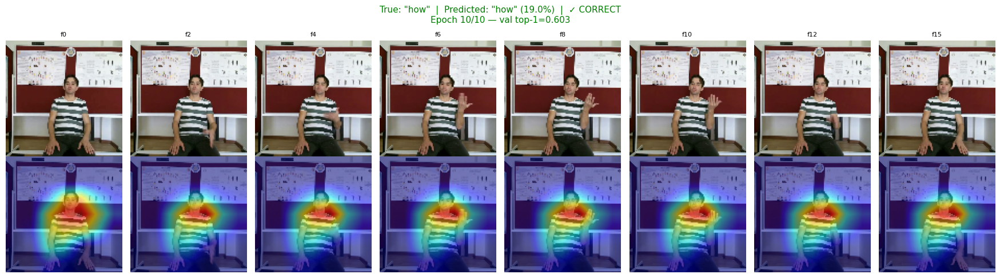


Done. Best val top-1: 60.32%


In [ ]:
# Use label smoothing + CosineAnnealing for better learning
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
history   = defaultdict(list)
best_top1 = 0.0


GRADCAM_IDX = 0


model.freeze_backbone()
optimizer = optim.AdamW(                          
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR_PHASE1, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=PHASE1_EP
)

for epoch in range(1, TOTAL_EP + 1):

    # Phase 2 transition
    if epoch == PHASE1_EP + 1:
        print('\n' + '─'*60)
        model.unfreeze_top_layers()
        optimizer = optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=LR_PHASE2, weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=PHASE2_EP
        )
        print('─'*60)

    tr_loss, tr_acc   = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
    vl_loss, vl_top1, vl_top5, _, _ = evaluate(model, val_loader, criterion, DEVICE)
    scheduler.step()

    history['tr_loss'].append(tr_loss)
    history['tr_acc'].append(tr_acc)
    history['vl_loss'].append(vl_loss)
    history['vl_top1'].append(vl_top1)
    history['vl_top5'].append(vl_top5)

    flag = ''
    if vl_top1 > best_top1:
        best_top1 = vl_top1
        torch.save(model.state_dict(), CKPT)
        flag = '  ← best'

    phase = 'Ph1' if epoch <= PHASE1_EP else 'Ph2'
    lr_now = optimizer.param_groups[0]['lr']
    print(f'Ep {epoch:02d}/{TOTAL_EP} [{phase}] | '
          f'Loss {tr_loss:.3f}  Acc {tr_acc:.3f} | '
          f'Val top-1 {vl_top1:.3f}  top-5 {vl_top5:.3f} | '
          f'LR {lr_now:.2e}{flag}')

    # GradCAM snapshot every 2 epochs
    if epoch % 2 == 0 or epoch == 1:
        print(f'  → GradCAM at epoch {epoch}:')
        show_gradcam(
            model, gradcam, val_ds, GRADCAM_IDX,
            title_extra=f'Epoch {epoch}/{TOTAL_EP} — val top-1={vl_top1:.3f}',
            save_path=f'gradcam_epoch_{epoch:02d}.png'
        )

print(f'\nDone. Best val top-1: {best_top1*100:.2f}%')

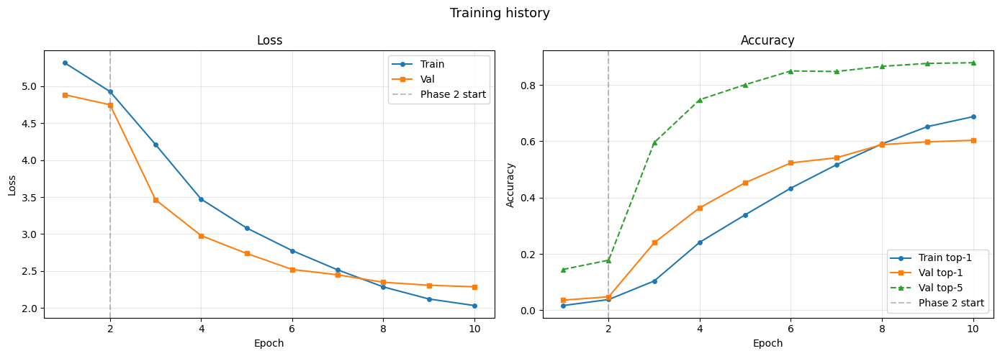

In [15]:
ep = range(1, TOTAL_EP + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ep, history['tr_loss'], label='Train', marker='o', ms=4)
axes[0].plot(ep, history['vl_loss'], label='Val',   marker='s', ms=4)
axes[0].axvline(PHASE1_EP, color='gray', ls='--', alpha=0.5, label='Phase 2 start')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')

axes[1].plot(ep, history['tr_acc'],  label='Train top-1', marker='o', ms=4)
axes[1].plot(ep, history['vl_top1'], label='Val top-1',   marker='s', ms=4)
axes[1].plot(ep, history['vl_top5'], label='Val top-5',   marker='^', ms=4, ls='--')
axes[1].axvline(PHASE1_EP, color='gray', ls='--', alpha=0.5, label='Phase 2 start')
axes[1].set_title('Accuracy'); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')

plt.suptitle('Training history', fontsize=13)
plt.tight_layout()
plt.savefig('viz_training_curves.png', dpi=150)
plt.show()

In [16]:
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
_, test_top1, test_top5, test_labels, test_probs = evaluate(model, test_loader, criterion, DEVICE)

print('='*50)
print('  TEST RESULTS')
print('='*50)
print(f'  Top-1 accuracy : {test_top1*100:.2f}%')
print(f'  Top-5 accuracy : {test_top5*100:.2f}%')
print(f'  Best val top-1 : {best_top1*100:.2f}%')
print('='*50)

  TEST RESULTS
  Top-1 accuracy : 58.27%
  Top-5 accuracy : 86.61%
  Best val top-1 : 60.32%


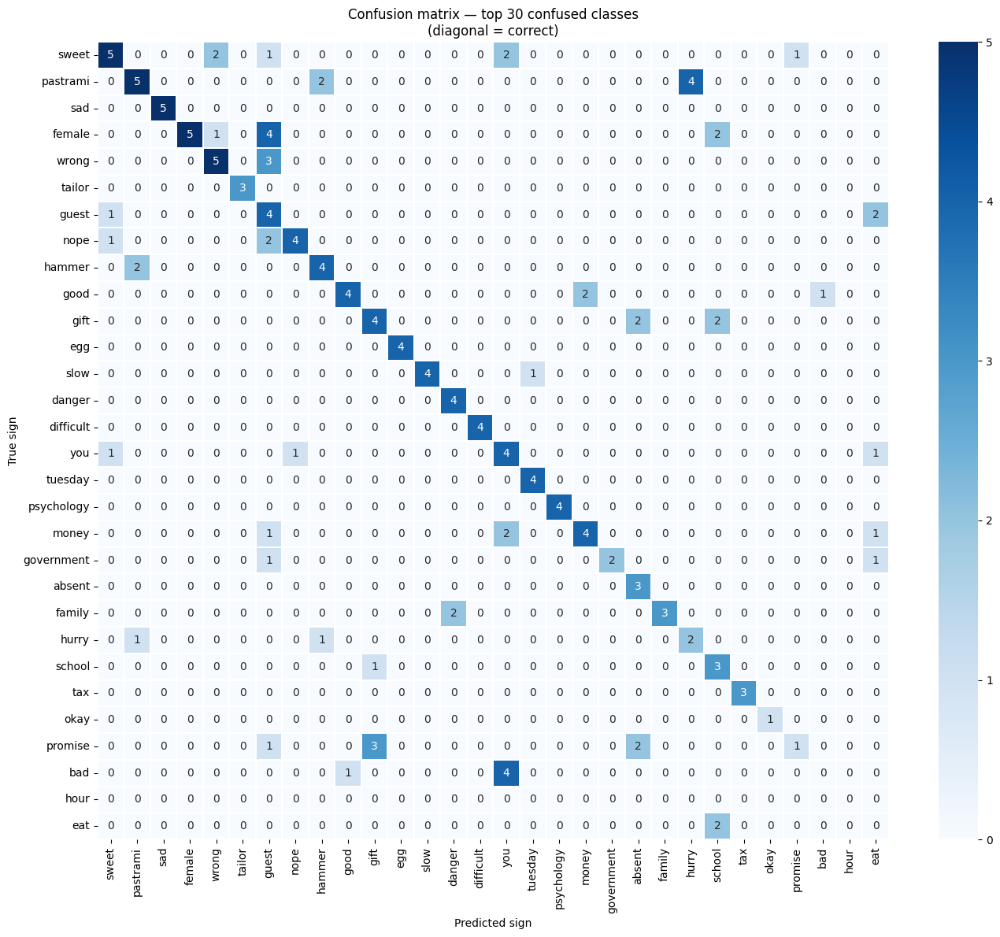

In [17]:
# Confusion matrix with sign word labels from CSV
preds = test_probs.argmax(axis=1)
cm    = confusion_matrix(test_labels, preds)
top30 = np.argsort(cm.sum(1) - np.diag(cm))[-30:]

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    cm[np.ix_(top30, top30)], annot=True, fmt='d', cmap='Blues',
    xticklabels=[GLOSS_MAP.get(int(i), str(i)) for i in top30],
    yticklabels=[GLOSS_MAP.get(int(i), str(i)) for i in top30],
    ax=ax, linewidths=0.3
)
ax.set_title('Confusion matrix — top 30 confused classes\n(diagonal = correct)')
ax.set_xlabel('Predicted sign'); ax.set_ylabel('True sign')
plt.tight_layout()
plt.savefig('viz_confusion_matrix.png', dpi=150)
plt.show()

Correct prediction:


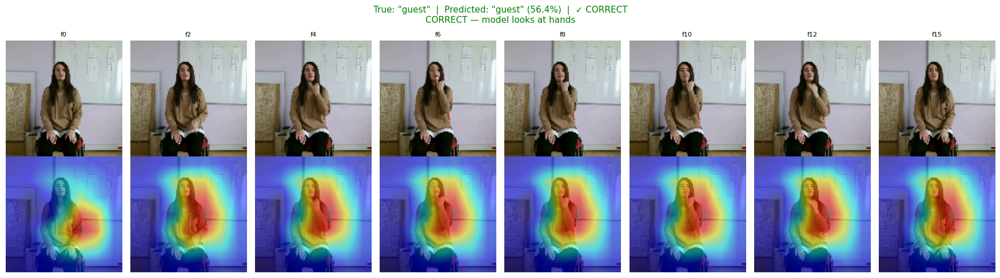

Wrong prediction:


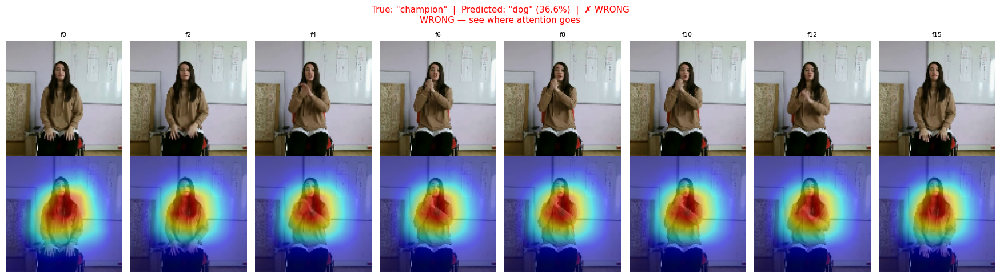

In [18]:
model.eval()
correct_idx = wrong_idx = None
with torch.no_grad():
    for i in range(min(300, len(test_ds))):
        v, lbl = test_ds[i]
        pred = model(v.unsqueeze(0).to(DEVICE)).argmax(1).item()
        if pred == lbl and correct_idx is None:  correct_idx = i
        if pred != lbl and wrong_idx   is None:  wrong_idx   = i
        if correct_idx is not None and wrong_idx is not None: break

print('Correct prediction:')
show_gradcam(model, gradcam, test_ds, correct_idx,
             title_extra='CORRECT — model looks at hands',
             save_path='viz_gradcam_correct.png')

print('Wrong prediction:')
show_gradcam(model, gradcam, test_ds, wrong_idx,
             title_extra='WRONG — see where attention goes',
             save_path='viz_gradcam_wrong.png')

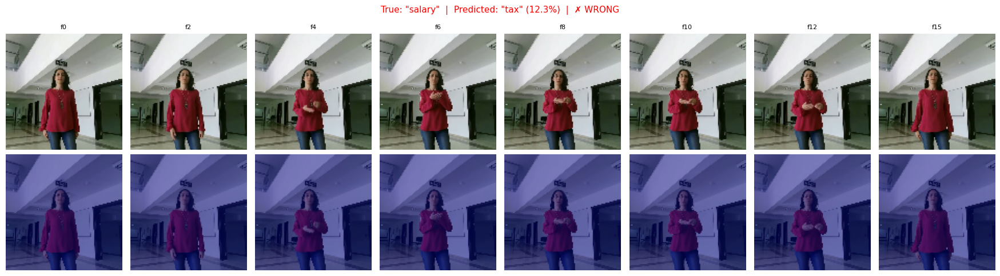

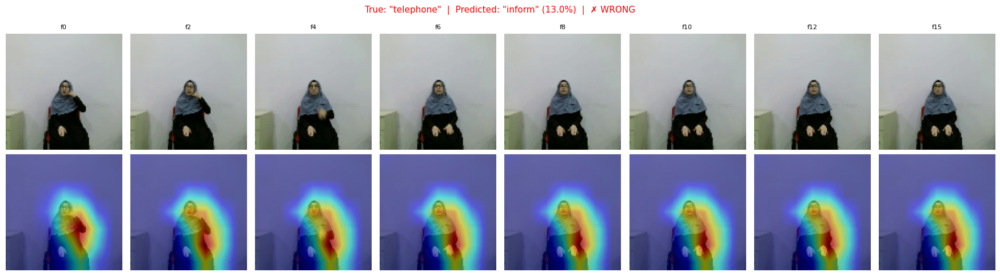

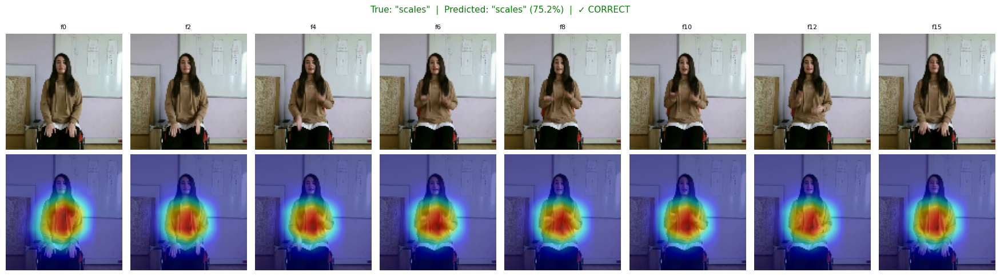

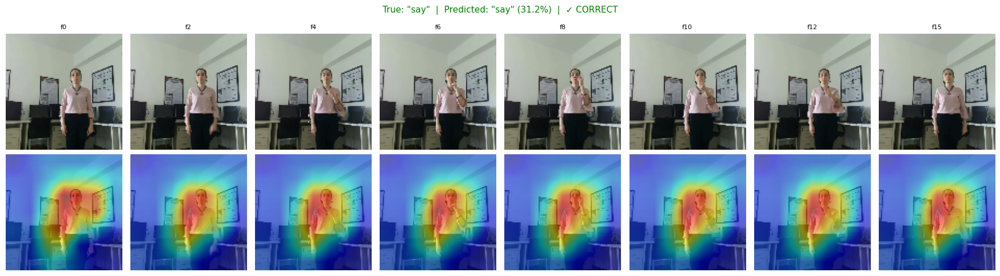

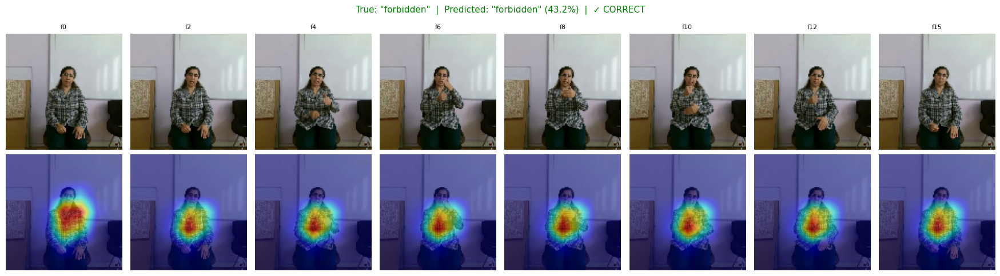

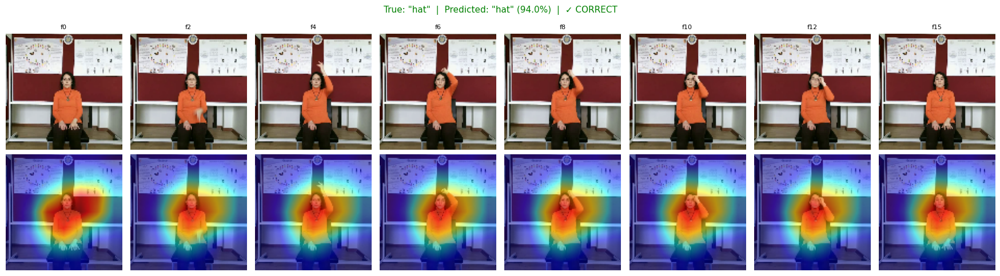

In [19]:
# 6 random test samples
np.random.seed(7)
for i, idx in enumerate(np.random.choice(len(test_ds), 6, replace=False)):
    show_gradcam(model, gradcam, test_ds, int(idx),
                 save_path=f'viz_gradcam_sample_{i}.png')

In [20]:
import torch

@torch.no_grad()
def predict(model, dataset, idx, top_k=5):
    """Predict sign and output English translation clearly."""
    model.eval()
    video, true_label = dataset[idx]
    probs  = torch.softmax(model(video.unsqueeze(0).to(DEVICE)), 1)[0].cpu().numpy()
    topk   = probs.argsort()[-top_k:][::-1]

    true_en = GLOSS_MAP_EN.get(true_label, str(true_label))
    true_tr = GLOSS_MAP_TR.get(true_label, str(true_label))

    print('=' * 65)
    print('  SIGN LANGUAGE PREDICTION')
    print('=' * 65)
    print(f'  True sign : class {true_label}')
    print(f'    Turkish : {true_tr}')
    print(f'    English : {true_en}')
    print(f'\n  Top-{top_k} predictions:')

    for rank, i in enumerate(topk):
        en   = GLOSS_MAP_EN.get(int(i), str(i))
        tr   = GLOSS_MAP_TR.get(int(i), str(i))
        conf = probs[i] * 100
        tick = '✓' if int(i) == true_label else ' '
        bar  = '█' * int(conf / 3)
        print(f'    {tick} #{rank+1}  EN: {en:20s}  TR: {tr:20s}  {conf:5.1f}%  {bar}')

    pred_en  = GLOSS_MAP_EN.get(int(topk[0]), str(topk[0]))
    pred_tr  = GLOSS_MAP_TR.get(int(topk[0]), str(topk[0]))
    correct  = int(topk[0]) == true_label
    status   = 'CORRECT ✓' if correct else 'WRONG ✗'

    print(f'\n  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━')
    print(f'  OUTPUT  English : "{pred_en}"')
    print(f'          Turkish : "{pred_tr}"')
    print(f'  Status  : {status}')
    print('=' * 65)


print('\nSample Predictions with English + Turkish translations:')
print()
for idx in np.random.choice(len(test_ds), 5, replace=False):
    predict(model, test_ds, int(idx))
    print()



Sample Predictions with English + Turkish translations:

  SIGN LANGUAGE PREDICTION
  True sign : class 81
    Turkish : hali
    English : carpet

  Top-5 predictions:
    ✓ #1  EN: carpet                TR: hali                   54.5%  ██████████████████
      #2  EN: trousers              TR: pantolon               20.1%  ██████
      #3  EN: tailor                TR: terzi                  16.2%  █████
      #4  EN: shopping              TR: alisveris               1.4%  
      #5  EN: heavy                 TR: agir                    1.1%  

  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  OUTPUT  English : "carpet"
          Turkish : "hali"
  Status  : CORRECT ✓

  SIGN LANGUAGE PREDICTION
  True sign : class 58
    Turkish : eczane
    English : pharmacy

  Top-5 predictions:
      #1  EN: show                  TR: gostermek              34.4%  ███████████
    ✓ #2  EN: pharmacy              TR: eczane                 25.6%  ████████
      #3  EN: lake                  TR: gol     

In [21]:
print('\n'+'='*58)
print('  — SIGN LANGUAGE RECOGNITION — RESULTS')
print('='*58)
print(f'  Dataset         : AUTSL — 226 Turkish sign classes')
print(f'  Gloss map       : loaded from train.csv ')
print(f'  Backbone        : R3D-18 Kinetics-400 pretrained')
print(f'  Training sample : {TRAIN_SAMPLE_FRAC*100:.0f}% ({len(train_ds)} videos)')
print(f'  Epochs          : {TOTAL_EP} (Ph1={PHASE1_EP} lr={LR_PHASE1}  Ph2={PHASE2_EP} lr={LR_PHASE2})')
print(f'  Best val top-1  : {best_top1*100:.2f}%')
print(f'  Test top-1      : {test_top1*100:.2f}%')
print(f'  Test top-5      : {test_top5*100:.2f}%')
print('='*58)


  — SIGN LANGUAGE RECOGNITION — RESULTS
  Dataset         : AUTSL — 226 Turkish sign classes
  Gloss map       : loaded from train.csv 
  Backbone        : R3D-18 Kinetics-400 pretrained
  Training sample : 50% (14003 videos)
  Epochs          : 10 (Ph1=2 lr=0.005  Ph2=8 lr=0.001)
  Best val top-1  : 60.32%
  Test top-1      : 58.27%
  Test top-5      : 86.61%


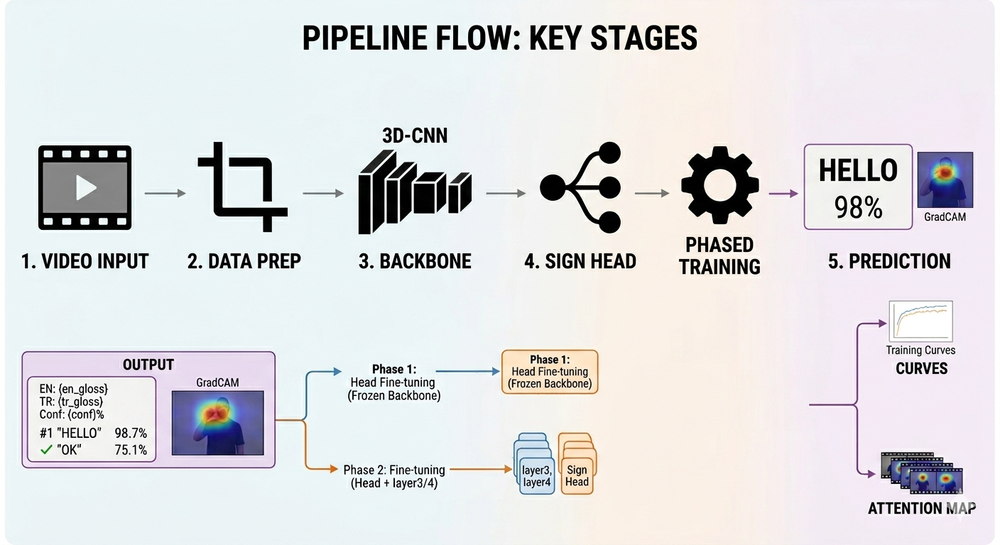

In [1]:
from IPython.display import Image, display
display(Image(filename='pipeline.png', width=800, height=700))